### 1. Importing the main libraries

In [1]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import shutil
import os

### 2. Loading data from Google Drive, unzipping, and creating a DataFrame

In [2]:
from google.colab import auth
from google.colab import drive

drive_ad = '/content/drive'
source = f'{drive_ad}/MyDrive/dl_seg/luna16-dp2d.zip'
destination = '/content/dataset'

# Accessing and Using Google Drive
auth.authenticate_user()
drive.mount(drive_ad)

shutil.copy(source, f'{destination}.zip')
print("Done", round(os.path.getsize(f'{destination}.zip') / (1024*1024), 2), "MB")

Mounted at /content/drive
Done 1725.94 MB


In [3]:
!unzip -q /content/dataset.zip -d /content/dataset  # Unzipping files

In [4]:
meta_path = f'{drive_ad}/MyDrive/dl_seg/metadata.csv'
df = pd.read_csv(meta_path)  # Creating a DataFrame

### 3. Data Organization and Review
* Reviewing and segregating the data required for the dataset
* Adding necessary elements to the data

In [5]:
# Separating the data and creating the 'has_nodule' column
def has_nodule_from_mask(path):
    mask_path = os.path.join(destination, path)

    if not os.path.exists(mask_path):
        return False

    mask = np.load(mask_path)
    return np.any(mask > 0)

df["has_nodule"] = df["nodule_mask_path"].apply(has_nodule_from_mask)

print(df["has_nodule"].value_counts())

has_nodule
False    5996
True      220
Name: count, dtype: int64


In [6]:
import numpy as np
import tensorflow as tf
import os
import cv2

class LungDataset(tf.keras.utils.Sequence):
    def __init__(self, df,
                 img_dir=f'{destination}/slices',
                 mask_dir=f'{destination}/masks/nodule_mask',
                 batch_size=8,
                 img_size=(512, 512),
                 shuffle=True,
                 augment=False,
                 **kwargs):

        super().__init__(**kwargs)

        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.batch_size = batch_size
        self.img_size = img_size
        self.shuffle = shuffle
        self.augment = augment
        self.indexes = np.arange(len(self.df))
        self.on_epoch_end()

    def __len__(self):
        return int(np.floor(len(self.df) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def _augment(self, img, mask):
        h, w = img.shape[:2]

        if np.random.rand() < 0.5:
            img = np.ascontiguousarray(img[:, ::-1])
            mask = np.ascontiguousarray(mask[:, ::-1])

        if np.random.rand() < 0.7:
            angle = np.random.uniform(-10, 10)
            scale = np.random.uniform(0.9, 1.1)

            M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, scale)
            img = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR,
                                 borderMode=cv2.BORDER_CONSTANT, borderValue=0)
            mask = cv2.warpAffine(mask, M, (w, h), flags=cv2.INTER_NEAREST,
                                  borderMode=cv2.BORDER_CONSTANT, borderValue=0)

        if np.random.rand() < 0.5:
            img = img * np.random.uniform(0.9, 1.1) + np.random.uniform(-10, 10)

        if np.random.rand() < 0.3:
            img = img + np.random.normal(0, 3, img.shape)

        img = np.clip(img, 0, 255).astype(np.float32)
        mask = (mask > 0.5).astype(np.float32)
        return img, mask

    def __getitem__(self, index):
        batch_indexes = self.indexes[index * self.batch_size : (index + 1) * self.batch_size]

        batch_images = []
        batch_masks = []

        for idx in batch_indexes:
            row = self.df.iloc[idx]

            img_name = os.path.basename(str(row['filename']))
            mask_name = os.path.basename(str(row['nodule_mask_path']))

            img_path = os.path.join(self.img_dir, img_name)
            mask_path = os.path.join(self.mask_dir, mask_name)

            img = np.load(img_path).astype(np.float32)
            img = np.clip(img, -1000.0, 400.0)
            img = ((img + 1000) / 1400) * 255.0

            if row.get('has_nodule', True) and os.path.exists(mask_path):
                mask = np.load(mask_path).astype(np.float32)
                mask = (mask > 0).astype(np.float32)
            else:
                mask = np.zeros(img.shape, dtype=np.float32)

            if img.shape[:2] != self.img_size:
                img = cv2.resize(img, self.img_size, interpolation=cv2.INTER_LINEAR)
            if mask.shape[:2] != self.img_size:
                mask = cv2.resize(mask, self.img_size, interpolation=cv2.INTER_NEAREST)

            if self.augment:
                img, mask = self._augment(img, mask)

            img = np.stack([img] * 3, axis=-1)
            mask = np.expand_dims(mask, axis=-1)

            batch_images.append(img)
            batch_masks.append(mask)

        return np.array(batch_images, dtype=np.float32), np.array(batch_masks, dtype=np.float32)

In [7]:
df_positive = df[df["has_nodule"] == True]
df_negative = df[df["has_nodule"] == False]

n = min(len(df_positive), len(df_negative))

df_balanced = pd.concat([
    df_positive.sample(n=n, random_state=42),
    df_negative.sample(n=n, random_state=42)
], ignore_index=True)

df_balanced = df_balanced.sample(
    frac=1, random_state=42
).reset_index(drop=True)

print("Balanced dataset:", df_balanced.shape)
print(df_balanced["has_nodule"].value_counts())

Balanced dataset: (440, 14)
has_nodule
False    220
True     220
Name: count, dtype: int64


### 4. Data segmentation

In [8]:
from sklearn.model_selection import GroupShuffleSplit
import pandas as pd

df_pos = df[df["has_nodule"] == True].copy()
df_neg = df[df["has_nodule"] == False].copy()

n_samples = min(len(df_pos), len(df_neg))

df_balanced = pd.concat([
    df_pos.sample(n=n_samples, random_state=42),
    df_neg.sample(n=n_samples, random_state=42)
], ignore_index=True)

df_balanced = df_balanced.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Balanced dataset:", df_balanced.shape)
print(df_balanced["has_nodule"].value_counts())

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        df_balanced,
        groups=df_balanced["original_scan"]
    )
)

train_df = df_balanced.iloc[train_idx].copy().reset_index(drop=True)
val_df = df_balanced.iloc[val_idx].copy().reset_index(drop=True)

print("\nTrain samples:", len(train_df))
print("Validation samples:", len(val_df))

print("\nTrain classes:")
print(train_df["has_nodule"].value_counts())

print("\nValidation classes:")
print(val_df["has_nodule"].value_counts())

overlap = set(train_df["original_scan"]) & set(val_df["original_scan"])
print("\nOverlapping scans:", len(overlap))

train_data = LungDataset(train_df, batch_size=8, shuffle=True,  augment=True)
val_data   = LungDataset(val_df,   batch_size=8, shuffle=False, augment=False)

print("\nTrain batches:", len(train_data))
print("Validation batches:", len(val_data))

Balanced dataset: (440, 14)
has_nodule
False    220
True     220
Name: count, dtype: int64

Train samples: 379
Validation samples: 61

Train classes:
has_nodule
False    191
True     188
Name: count, dtype: int64

Validation classes:
has_nodule
True     32
False    29
Name: count, dtype: int64

Overlapping scans: 0

Train batches: 47
Validation batches: 7


In [9]:
sample_x, sample_y = train_data[0]
print("sample x:", len(sample_x))
print("sample y:", len(sample_y))

sample x: 8
sample y: 8


### 5. Importing a pre-trained model and training it on the project's data
* In this part of the project, we use EfficientNetB0.

In [10]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0

encoder = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(512, 512, 3)
)

skip_names = [
    "block2a_expand_activation",
    "block3a_expand_activation",
    "block4a_expand_activation",
    "block6a_expand_activation"
]

skip_outputs = [
    encoder.get_layer(name).output
    for name in skip_names
]

encoder_model = Model(inputs=encoder.input, outputs=skip_outputs)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [11]:
for l in encoder_model.layers:
    l.trainable = False

trainable_layers = [
    layer.name
    for layer in encoder.layers
    if layer.trainable and layer.weights
]

print("Trainable encoder layers:", len(trainable_layers))
print("Last trainable layers:")
print(trainable_layers[-15:])

Trainable encoder layers: 40
Last trainable layers:
['block6d_bn', 'block6d_se_reduce', 'block6d_se_expand', 'block6d_project_conv', 'block6d_project_bn', 'block7a_expand_conv', 'block7a_expand_bn', 'block7a_dwconv', 'block7a_bn', 'block7a_se_reduce', 'block7a_se_expand', 'block7a_project_conv', 'block7a_project_bn', 'top_conv', 'top_bn']


### 6. Creating Hand-Drawn Layers
* U-Net Architecture

In [12]:
# Decoder layers

def decoder_block(x, skip, filters):

    x = layers.Conv2DTranspose(
        filters,
        (2, 2),
        strides=(2, 2),
        padding="same"
    )(x)

    x = layers.Concatenate()([x, skip])

    x = layers.Conv2D(
        filters,
        (3, 3),
        padding="same",
        activation="relu"
    )(x)

    x = layers.BatchNormalization(momentum=0.9)(x)

    x = layers.Conv2D(
        filters,
        (3, 3),
        padding="same",
        activation="relu"
    )(x)

    x = layers.BatchNormalization(momentum=0.9)(x)

    return x

In [13]:
def build_transfer_unet():
    inputs = layers.Input(shape=(512, 512, 3))
    skip1, skip2, skip3, skip4 = encoder_model(inputs)

    x = skip4
    x = decoder_block(x, skip3, 256)
    x = decoder_block(x, skip2, 128)
    x = decoder_block(x, skip1, 64)

    s0 = layers.Rescaling(1.0 / 255)(inputs)
    s0 = layers.Conv2D(16, 3, padding="same", activation="relu")(s0)
    s0 = layers.BatchNormalization(momentum=0.9)(s0)
    s0 = layers.Conv2D(16, 3, padding="same", activation="relu")(s0)

    x = layers.Conv2DTranspose(32, 2, strides=2, padding="same")(x)
    x = layers.Concatenate()([x, s0])
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)

    outputs = layers.Conv2D(
        1, 1, activation="sigmoid",
        bias_initializer=tf.keras.initializers.Constant(-5.0)
    )(x)
    return Model(inputs, outputs)

In [14]:
model = build_transfer_unet()

### 7. Developing Evaluation Metrics
* Dice for segmentation

In [19]:
import tensorflow as tf
import tensorflow.keras.backend as K

# Dice Coefficient - Validation Metric
def val_dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = K.flatten(K.cast(y_true, "float32"))
    y_pred_f = K.flatten(K.cast(y_pred, "float32"))

    intersection = K.sum(y_true_f * y_pred_f)

    return (2.0 * intersection + smooth) / (
        K.sum(y_true_f) + K.sum(y_pred_f) + smooth
    )

# Focal Tversky Loss - Training Loss
def focal_tversky_loss(y_true, y_pred, alpha=0.7, beta=0.3, gamma=1.3, smooth=1e-6):

    y_true = K.flatten(K.cast(y_true, "float32"))
    y_pred = K.flatten(K.cast(y_pred, "float32"))

    tp = K.sum(y_true * y_pred)
    fp = K.sum((1 - y_true) * y_pred)
    fn = K.sum(y_true * (1 - y_pred))

    tversky_index = (tp + smooth) / (
        tp + alpha * fp + beta * fn + smooth
    )

    return K.pow(1.0 - tversky_index, gamma)

### 8. Model Training

In [20]:
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, EarlyStopping

MODELS = f'{drive_ad}/MyDrive/dl_seg/models'
os.makedirs(MODELS, exist_ok=True)

# Adding callbacks for project control
callbacks = [
    ModelCheckpoint('dl_segmentation_model.keras', monitor="val_val_dice_coef",
                    mode="max", save_best_only=True, verbose=1),

    ReduceLROnPlateau(monitor="val_val_dice_coef", mode="max", factor=0.55,
                      patience=6, min_lr=1e-5, verbose=1),

    EarlyStopping(monitor="val_val_dice_coef", mode="max", patience=20,
                  min_delta=0.0001, restore_best_weights=True, verbose=1)
    ]

In [22]:
model.compile(optimizer=tf.keras.optimizers.Adam(3e-4),
              loss=focal_tversky_loss,
              metrics=[val_dice_coef])

In [23]:
model.fit(train_data,
          validation_data=val_data,
          epochs=60,
          callbacks=callbacks)

Epoch 1/60
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 717ms/step - loss: 0.8887 - val_dice_coef: 0.1078
Epoch 1: val_val_dice_coef improved from None to 0.29108, saving model to dl_segmentation_model.keras

Epoch 1: finished saving model to dl_segmentation_model.keras
47/47 ━━━━━━━━━━━━━━━━━━━━ 77s 958ms/step - loss: 0.8321 - val_dice_coef: 0.1571 - val_loss: 0.6608 - val_val_dice_coef: 0.2911 - learning_rate: 3.0000e-04
Epoch 2/60
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 668ms/step - loss: 0.6352 - val_dice_coef: 0.3025
Epoch 2: val_val_dice_coef improved from 0.29108 to 0.46622, saving model to dl_segmentation_model.keras

Epoch 2: finished saving model to dl_segmentation_model.keras
47/47 ━━━━━━━━━━━━━━━━━━━━ 35s 735ms/step - loss: 0.5904 - val_dice_coef: 0.3382 - val_loss: 0.4485 - val_val_dice_coef: 0.4662 - learning_rate: 3.0000e-04
Epoch 3/60
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 685ms/step - loss: 0.5806 - val_dice_coef: 0.3353
Epoch 3: val_val_dice_coef did not improve from 0.46622
47/47 ━━━━━━━━━━━━━━━━━━━━

### 9. Performance Evaluation

In [24]:
import cv2

def evaluate_val(model, data, thresholds=(0.3, 0.4, 0.5, 0.6, 0.7), min_area=8):
    P, G = [], []

    for i in range(len(data)):
        x, y = data[i]
        P.append(model.predict(x, verbose=0)[..., 0])
        G.append(y[..., 0] > 0.5)

    P, G = np.concatenate(P), np.concatenate(G)
    n_pos = int((G.reshape(len(G), -1).sum(1) > 0).sum())

    for thr in thresholds:
        pm = P > thr
        dice = 2 * (pm & G).sum() / (pm.sum() + G.sum() + 1e-7)
        hit, fp = 0, 0

        for p, g in zip(pm, G):
            n_cc, lab, st, _ = cv2.connectedComponentsWithStats(
                p.astype(np.uint8), connectivity=8)
            found = False

            for k in range(1, n_cc):
                if st[k, cv2.CC_STAT_AREA] < min_area:
                    continue
                if (g & (lab == k)).any():
                    found = True
                else:
                    fp += 1

            hit += int(found and g.any())

        print(f"thr={thr}: Dice={dice:.3f} | detected {hit}/{n_pos} | FP components={fp}")

evaluate_val(model, val_data)

thr=0.3: Dice=0.625 | detected 18/29 | FP components=12
thr=0.4: Dice=0.626 | detected 17/29 | FP components=12
thr=0.5: Dice=0.626 | detected 17/29 | FP components=12
thr=0.6: Dice=0.626 | detected 17/29 | FP components=12
thr=0.7: Dice=0.627 | detected 17/29 | FP components=12


### 10. Generating images for an intuitive understanding of the model's comprehension and for visual evaluation.

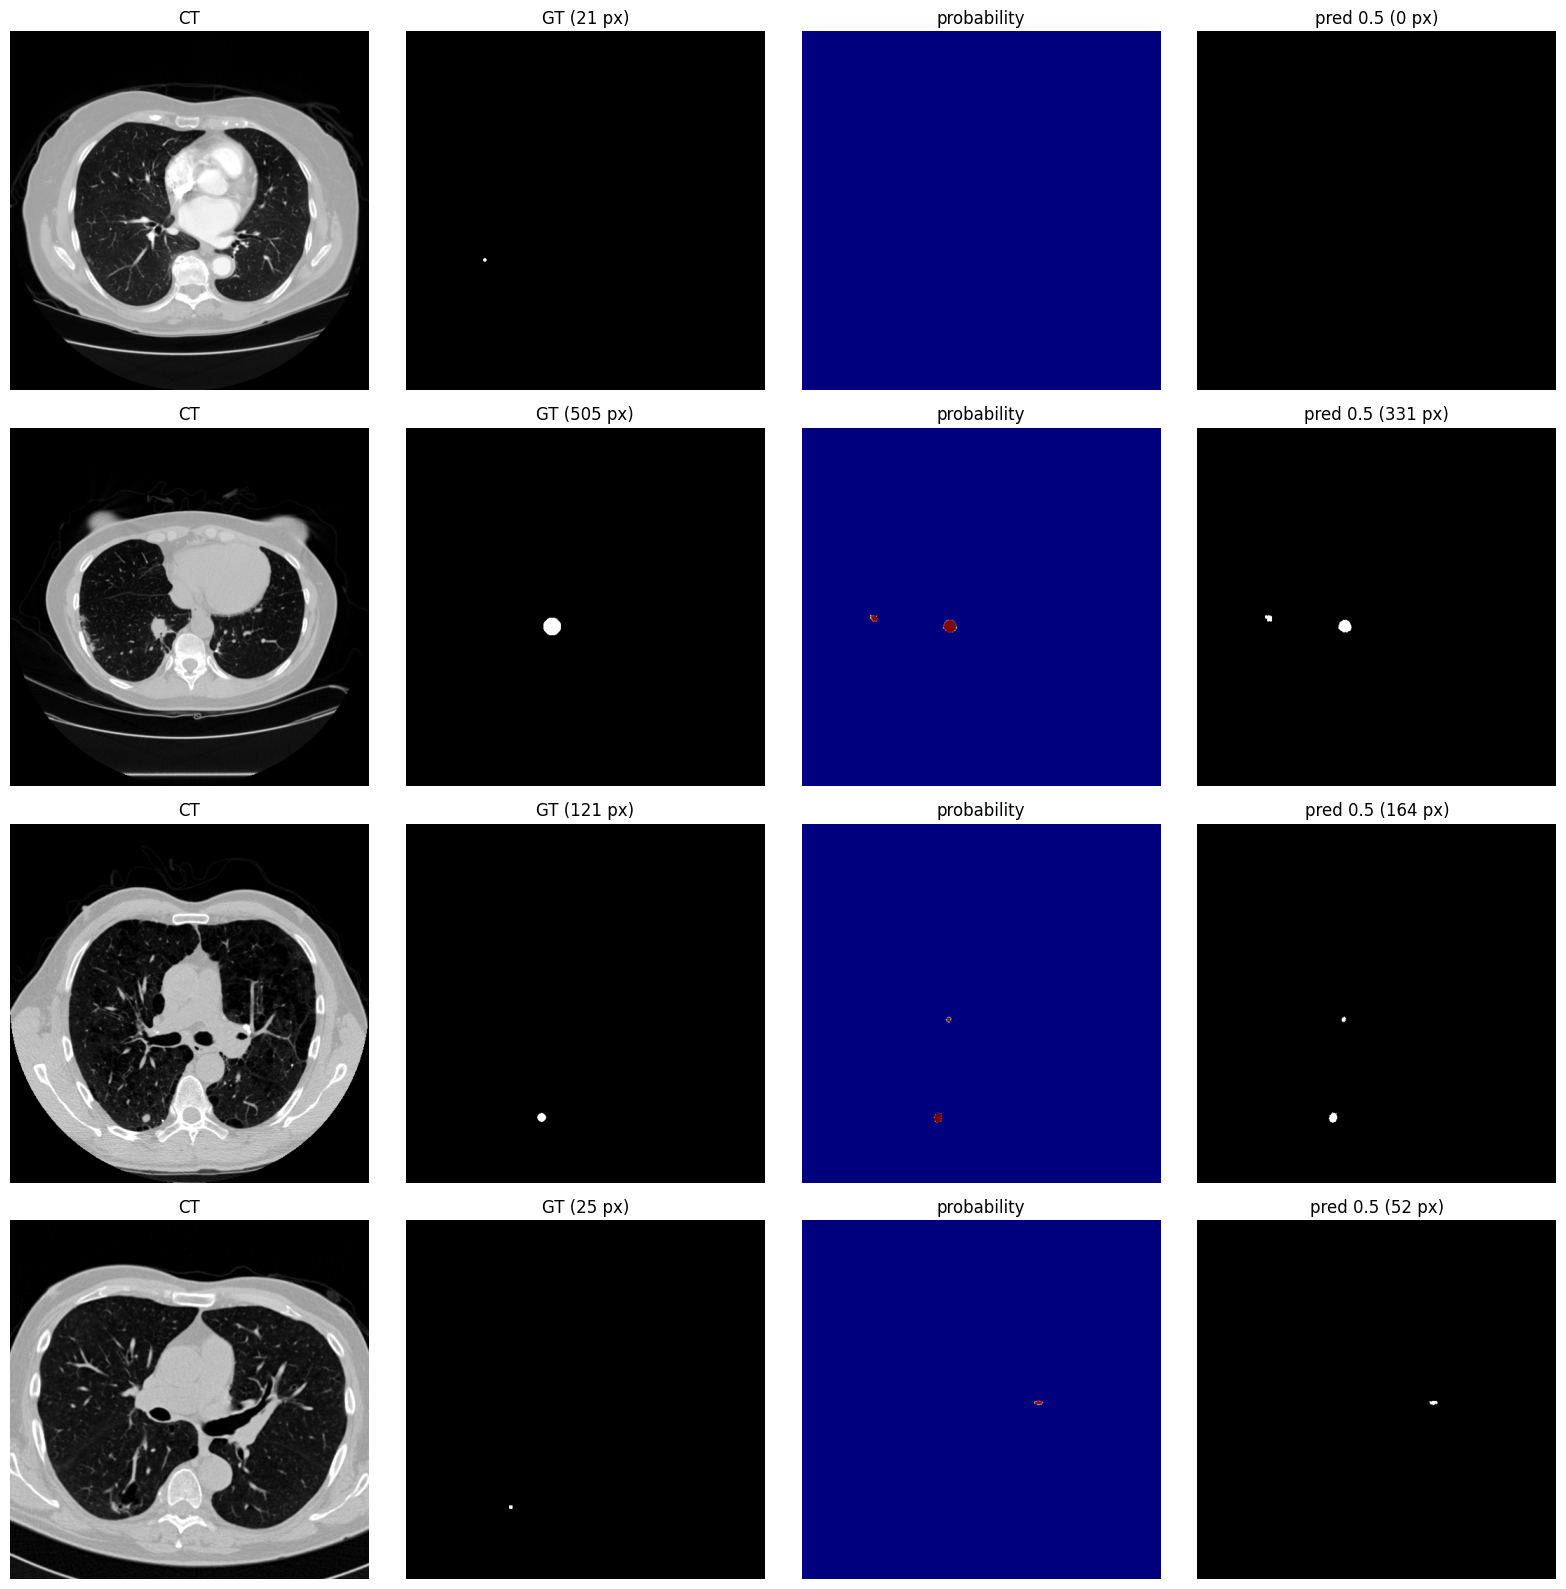

In [25]:
images, masks = val_data[0]
preds = model.predict(images, verbose=0)

pos = [i for i in range(len(images)) if masks[i].sum() > 0][:4]
fig, ax = plt.subplots(len(pos), 4, figsize=(16, 4*len(pos)))

for r, i in enumerate(pos):
    gt, p = masks[i,:,:,0] > 0.5, preds[i,:,:,0]

    ax[r,0].imshow(images[i,:,:,0], cmap="gray"); ax[r,0].set_title("CT")
    ax[r,1].imshow(gt, cmap="gray"); ax[r,1].set_title(f"GT ({int(gt.sum())} px)")
    ax[r,2].imshow(p, cmap="jet", vmin=0, vmax=1); ax[r,2].set_title("probability")
    ax[r,3].imshow(p > 0.5, cmap="gray"); ax[r,3].set_title(f"pred 0.5 ({int((p>0.5).sum())} px)")

    for a in ax[r]: a.axis("off")

plt.tight_layout()
plt.show()